## 1. Data checks

[![content: AI-generated](../_static/badges/ai-generated.svg)](ai-acknowledgement) [![content: human-reviewed & edited](../_static/badges/human-reviewed-edited.svg)](ai-acknowledgement)

Three checks that the curated table is sound before anything is modelled: its structure, how far back each predictor goes, and whether two raw series match their quarterly values. They are safety checks. None of them changed a modelling choice.

### Structure and integrity

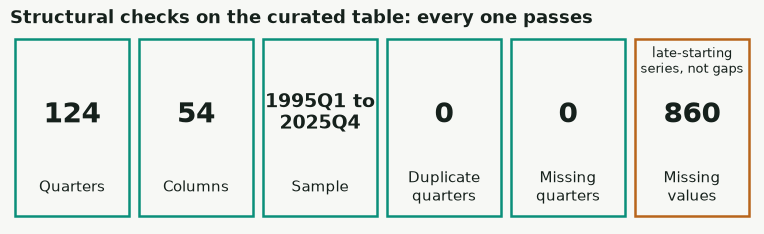

In [2]:
# EDA sees only quarters up to the forecast origin; later quarters are held out for benchmarking.
df = restrict_to_eda_window(pd.read_csv(DATA_PATH))
df['quarter_period'] = pd.PeriodIndex(df['quarter'], freq='Q')
df['quarter_start'] = df['quarter_period'].dt.to_timestamp(how='start')
df = df.sort_values('quarter_period').reset_index(drop=True)

# src.features owns these rate-change transforms for future curated rebuilds.
# Keep this compatibility block so the current checked-in curated CSV can still
# execute before the generated dataset is refreshed. Rate levels are percentages,
# so differences are percentage-point moves rather than proportional log changes.
RATE_CHANGE_LAG_MAP = {
    'cash_rate': [1],
    'unemployment_rate': [1, 2],
}
for source_col, lags in RATE_CHANGE_LAG_MAP.items():
    if source_col not in df:
        continue
    change_col = f'{source_col}_change'
    df[change_col] = df[source_col].diff()
    for lag in lags:
        df[f'{change_col}_lag{lag}'] = df[change_col].shift(lag)

df_model = df.drop(columns=['quarter_period', 'quarter_start'])

schema = pd.DataFrame({'column': df_model.columns, 'dtype': df_model.dtypes.astype(str).values})

validation_records = [record.as_dict() for record in validate_curated_dataset(df_model)]
validation_records.append(validate_curated_with_pandera(df_model).as_dict())
validation_summary = pd.DataFrame(validation_records)

quarters = df['quarter_period']
expected_quarters = pd.period_range(quarters.min(), quarters.max(), freq='Q')
integrity_summary = pd.DataFrame([
    {'check': 'row_count', 'value': len(df)},
    {'check': 'column_count', 'value': len(df_model.columns)},
    {'check': 'start_quarter', 'value': str(quarters.min())},
    {'check': 'end_quarter', 'value': str(quarters.max())},
    {'check': 'duplicate_quarters', 'value': int(df['quarter'].duplicated().sum())},
    {'check': 'missing_quarters', 'value': int(len(expected_quarters.difference(quarters)))},
    {'check': 'is_sorted', 'value': bool(quarters.is_monotonic_increasing)},
])
with plt.rc_context(BOOK_STYLE):
    kv = dict(zip(integrity_summary["check"], integrity_summary["value"]))
    n_missing_values = int(validation_summary.loc[0, "missing_values"])
    tiles = [
        ("Quarters", f"{kv['row_count']}", ACCENT),
        ("Columns", f"{kv['column_count']}", ACCENT),
        ("Sample", f"{kv['start_quarter']} to\n{kv['end_quarter']}", ACCENT),
        ("Duplicate\nquarters", f"{kv['duplicate_quarters']}", ACCENT),
        ("Missing\nquarters", f"{kv['missing_quarters']}", ACCENT),
        ("Missing\nvalues", f"{n_missing_values}", HIGHLIGHT),
    ]
    fig, ax = plt.subplots(figsize=(9.6, 2.5))
    ax.set_xlim(0, len(tiles)); ax.set_ylim(0, 1); ax.axis("off")
    for i, (label, value, colour) in enumerate(tiles):
        ax.add_patch(plt.Rectangle((i + 0.04, 0.04), 0.92, 0.92, facecolor=PAPER, edgecolor=colour, linewidth=1.8))
        ax.text(i + 0.5, 0.58, value, ha="center", va="center", fontsize=20 if "\n" not in value else 14,
                fontweight="bold", linespacing=1.1)
        ax.text(i + 0.5, 0.19, label, ha="center", va="center", fontsize=11)
    ax.text(5.5, 0.93, "late-starting\nseries, not gaps", ha="center", va="top", fontsize=9, color=INK)
    ax.set_title("Structural checks on the curated table: every one passes", loc="left", fontsize=13, fontweight="bold")
    plt.show()

# The screens in this appendix cover headline CPI only, so the other CPI measure is left out from here on.
other_cpi_cols = [column for column in df.columns if 'trimmed_mean' in column]
df = df.drop(columns=other_cpi_cols)
df_model = df_model.drop(columns=other_cpi_cols)

**Interpretation.** Every structural check passes: 124 quarters from 1995Q1 to 2025Q4,
zero duplicate or missing quarters, correctly sorted, and every core column (`cpi_yoy`,
`cash_rate`, etc.) individually validated `PASS`. The 860 missing *values* flagged above aren't a data-quality failure; they're columns that simply don't exist yet
at the start of the sample (e.g. `wage_price_index` only has 114 of 124 possible
observations, since ABS wage-price data collection started later than CPI). The next check quantifies this, variable by variable.

### Missing values and coverage

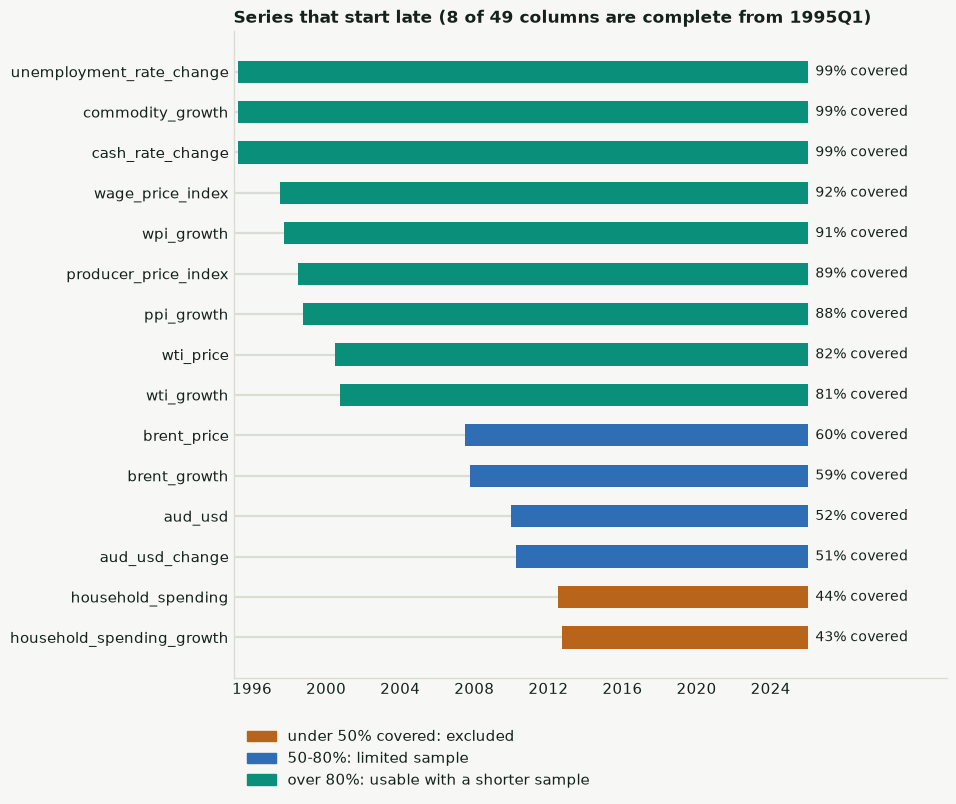

In [3]:
def first_last_non_null_date(frame: pd.DataFrame, column: str) -> tuple[str | None, str | None]:
    mask = frame[column].notna()
    if not mask.any():
        return None, None
    return str(frame.loc[mask, 'quarter_period'].iloc[0]), str(frame.loc[mask, 'quarter_period'].iloc[-1])


def coverage_class(coverage_pct: float) -> str:
    if coverage_pct >= 0.95:
        return 'core_long_sample_candidate'
    if coverage_pct >= 0.80:
        return 'shorter_sample_candidate'
    if coverage_pct >= 0.50:
        return 'limited_sample_candidate'
    return 'exclude_low_coverage'


sample_start = str(df['quarter_period'].min())
coverage_rows = []
for column in df_model.columns:
    if column == 'quarter':
        continue
    first_non_null, last_non_null = first_last_non_null_date(df, column)
    missing_count = int(df[column].isna().sum())
    available_observations = int(df[column].notna().sum())
    missing_pct = missing_count / len(df)
    coverage_pct = available_observations / len(df)
    late_start_reduces_sample = first_non_null not in {None, sample_start}
    substantial_missingness = missing_pct >= MATERIAL_MISSING_THRESHOLD
    coverage_rows.append({
        'variable': column,
        'available_observations': available_observations,
        'non_null_rows': available_observations,
        'missing_count': missing_count,
        'missing_pct': missing_pct,
        'coverage_pct': coverage_pct,
        'start_quarter': sample_start,
        'first_non_null': first_non_null,
        'last_non_null': last_non_null,
        'late_start_reduces_estimation_sample': bool(late_start_reduces_sample),
        'substantial_missingness_warning': bool(substantial_missingness),
        # Backward-compatible name used later in the notebook; this now means
        # genuinely substantial missingness, not merely starting after 1995Q1.
        'material_early_missingness': bool(substantial_missingness),
        'coverage_class': coverage_class(coverage_pct),
    })

coverage = pd.DataFrame(coverage_rows).sort_values(['missing_pct', 'variable'], ascending=[False, True])
with plt.rc_context(BOOK_STYLE):
    late = coverage[(coverage["first_non_null"] != coverage["start_quarter"]) & ~coverage["variable"].str.contains("_lag")].copy()
    late["start"] = pd.PeriodIndex(late["first_non_null"], freq="Q").to_timestamp()
    late["end"] = pd.PeriodIndex(late["last_non_null"], freq="Q").to_timestamp(how="end")
    late = late.sort_values("start", ascending=False).reset_index(drop=True)
    colours = {"exclude_low_coverage": HIGHLIGHT, "limited_sample_candidate": BLUE, "shorter_sample_candidate": ACCENT,
               "core_long_sample_candidate": ACCENT}
    sample_start = pd.Period(coverage["start_quarter"].iloc[0], freq="Q").to_timestamp()
    fig, ax = plt.subplots(figsize=(9.2, 0.4 * len(late) + 2.4))
    for y, r in late.iterrows():
        ax.barh(y, (r["end"] - r["start"]).days, left=r["start"], color=colours.get(r["coverage_class"], MUTED), height=0.55)
        ax.plot([sample_start, r["start"]], [y, y], color=GRID, linewidth=1.6, zorder=0)
        ax.text(r["end"] + pd.Timedelta(days=150), y, f"{r['coverage_pct'] * 100:.0f}% covered", va="center", fontsize=10)
    ax.set_yticks(range(len(late)), late["variable"], fontsize=10.5)
    ax.set_xlim(sample_start, pd.Timestamp("2033-06-30"))
    ax.set_xticks(pd.to_datetime([f"{y}-01-01" for y in range(1996, 2028, 4)]), [str(y) for y in range(1996, 2028, 4)])
    complete = int((coverage["first_non_null"] == coverage["start_quarter"]).sum())
    ax.set_title(f"Series that start late ({complete} of {len(coverage)} columns are complete from {coverage['start_quarter'].iloc[0]})",
                 loc="left", fontsize=12.5, fontweight="bold")
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=colours[k], label=t) for t, k in [("under 50% covered: excluded", "exclude_low_coverage"),
                                                                    ("50-80%: limited sample", "limited_sample_candidate"),
                                                                    ("over 80%: usable with a shorter sample", "shorter_sample_candidate")]],
              frameon=False, fontsize=10.5, loc="upper left", bbox_to_anchor=(0.0, -0.06))
    plt.show()
pass

**Interpretation.** The worst-coverage predictors are `household_spending_growth`
(43% coverage, doesn't start until 2012Q4), `aud_usd_change` (51%, starts 2010Q2), and
`brent_growth` (59%, starts 2007Q4). They aren't broken data; they're series whose underlying
collection or the project's own retrieval simply doesn't reach back to 1995Q1. The
`coverage_class` column turns this into an explicit modelling decision (`exclude_low_coverage`
vs. `limited_sample_candidate`) rather than a silent one, and it's the reason those same
variables show up later in [§4](04_lead_lag_correlation)/[§5](05_granger_causality) with much smaller `n_obs` than series like `cpi_qoq` or
`cash_rate` that are complete from the start.

### Raw source spot check

The notebook primarily validates the curated quarterly modelling table. This light spot check reconciles two representative raw inputs against the curated quarterly values using the ETL rule in `src.transform.to_quarterly()` and the source-specific aggregation configured in `src.build_curated_dataset.SeriesSpec`. It is not a full raw-source audit.

cash_rate: monthly source, 372 raw rows, 1995-01-01 to 2025-12-01, 0 duplicate dates
wti_price: daily trading days source, 6367 raw rows, 2000-08-23 to 2025-12-31, 0 duplicate dates


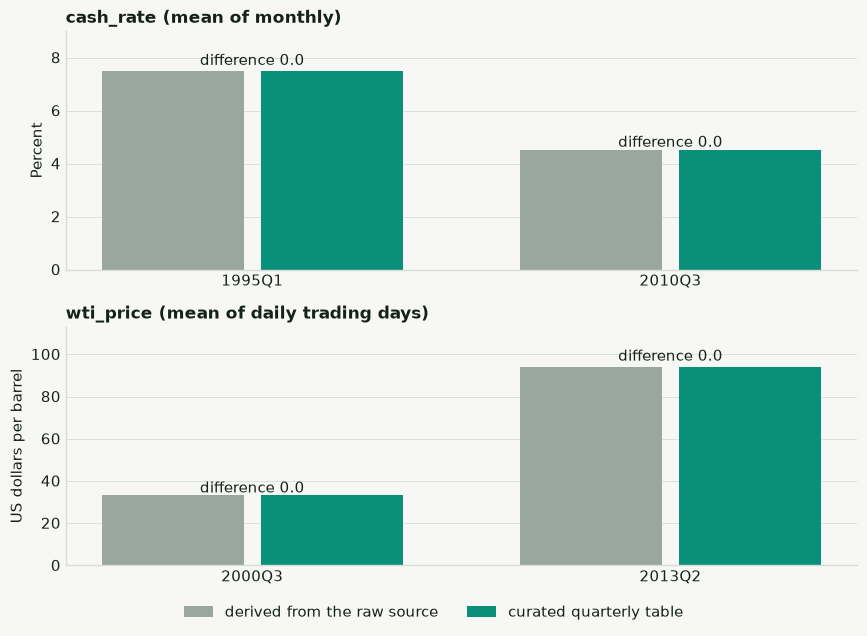

This spot check verifies representative monthly and daily inputs only. Full source-level validation remains an ETL/data-quality task; this EDA validates the curated quarterly table used for modelling.

In [4]:
from src.transform import to_quarterly
from src.validation import find_date_column

spot_specs = [
    {
        'variable': 'cash_rate',
        'source_family': 'RBA cash rate',
        'source_frequency': 'monthly',
        'path': latest_dataset_path(ROOT / 'dataset' / 'rba' / 'cash_rate_1995_2026.csv'),
        'value_col': 'cash_rate',
        'agg': 'mean',
    },
    {
        'variable': 'wti_price',
        'source_family': 'market WTI crude oil',
        'source_frequency': 'daily trading days',
        'path': latest_dataset_path(ROOT / 'dataset' / 'market' / 'wti_crude_oil_1995_2025.csv'),
        'value_col': 'Close',
        'agg': 'mean',
    },
]

spot_rows = []
frequency_rows = []
curated_lookup = df_model.set_index('quarter')
for spec in spot_specs:
    raw = pd.read_csv(spec['path'])
    date_col = find_date_column(raw)
    raw_quarters = pd.to_datetime(raw[date_col], errors='coerce').dt.to_period('Q')
    raw = raw.loc[raw_quarters.isna() | (raw_quarters <= EDA_END_QUARTER)]
    parsed_dates = pd.to_datetime(raw[date_col], errors='coerce')
    parsed_non_null = parsed_dates.dropna().sort_values()
    inferred_frequency = pd.infer_freq(parsed_non_null.head(12)) if len(parsed_non_null) >= 12 else None
    median_spacing_days = parsed_non_null.diff().dt.days.dropna().median() if len(parsed_non_null) > 1 else np.nan
    duplicate_dates = int(parsed_dates.duplicated().sum())

    frequency_rows.append({
        'variable': spec['variable'],
        'source_family': spec['source_family'],
        'source_frequency': spec['source_frequency'],
        'raw_rows': int(len(raw)),
        'date_col': date_col,
        'start_date': parsed_non_null.min().date() if len(parsed_non_null) else None,
        'end_date': parsed_non_null.max().date() if len(parsed_non_null) else None,
        'duplicate_dates': duplicate_dates,
        'inferred_frequency_head': inferred_frequency,
        'median_spacing_days': median_spacing_days,
    })

    quarterly = to_quarterly(raw, value_col=spec['value_col'], output_col=spec['variable'], agg=spec['agg'], date_col=date_col)
    common_quarters = [quarter for quarter in quarterly['quarter'] if quarter in curated_lookup.index and pd.notna(curated_lookup.loc[quarter, spec['variable']])]
    sample_quarters = []
    if common_quarters:
        sample_quarters.append(common_quarters[0])
    if len(common_quarters) > 1:
        sample_quarters.append(common_quarters[len(common_quarters) // 2])
    for quarter in dict.fromkeys(sample_quarters):
        raw_value = float(quarterly.loc[quarterly['quarter'] == quarter, spec['variable']].iloc[0])
        curated_value = float(curated_lookup.loc[quarter, spec['variable']])
        spot_rows.append({
            'variable': spec['variable'],
            'source_frequency': spec['source_frequency'],
            'aggregation_rule': spec['agg'],
            'spot_quarter': quarter,
            'raw_derived_value': raw_value,
            'curated_value': curated_value,
            'absolute_difference': abs(raw_value - curated_value),
            'match': bool(np.isclose(raw_value, curated_value, rtol=1e-8, atol=1e-8)),
        })

raw_frequency_spot_check = pd.DataFrame(frequency_rows)
raw_curated_reconciliation = pd.DataFrame(spot_rows)
for r in raw_frequency_spot_check.itertuples():
    print(f"{r.variable}: {r.source_frequency} source, {r.raw_rows} raw rows, {r.start_date} to {r.end_date}, "
          f"{r.duplicate_dates} duplicate dates")
with plt.rc_context(BOOK_STYLE):
    rc = raw_curated_reconciliation.copy()
    variables = list(dict.fromkeys(rc["variable"]))
    units = {"cash_rate": "Percent", "wti_price": "US dollars per barrel"}
    fig, axes = plt.subplots(len(variables), 1, figsize=(8.8, 3.2 * len(variables)))
    for ax, var in zip(np.atleast_1d(axes), variables):
        sub = rc[rc["variable"] == var].reset_index(drop=True)
        x = np.arange(len(sub))
        ax.bar(x - 0.19, sub["raw_derived_value"], width=0.34, color=MUTED, label="derived from the raw source")
        ax.bar(x + 0.19, sub["curated_value"], width=0.34, color=ACCENT, label="curated quarterly table")
        for xi, r in sub.iterrows():
            ax.text(xi, max(r["raw_derived_value"], r["curated_value"]) * 1.03, f"difference {r['absolute_difference']:.1f}",
                    ha="center", fontsize=10.5)
        ax.set_xticks(x, sub["spot_quarter"], fontsize=10.5)
        ax.set_ylim(0, sub[["raw_derived_value", "curated_value"]].to_numpy().max() * 1.2)
        ax.set_ylabel(units.get(var, ""))
        ax.set_title(f"{var} ({sub['aggregation_rule'].iloc[0]} of {sub['source_frequency'].iloc[0]})", loc="left",
                     fontsize=12, fontweight="bold")
        ax.grid(axis="y", visible=True)
    handles, labels = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(handles, labels, frameon=False, fontsize=10.5, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0))
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    plt.show()

display(Markdown('This spot check verifies representative monthly and daily inputs only. Full source-level validation remains an ETL/data-quality task; this EDA validates the curated quarterly table used for modelling.'))

**Interpretation.** Both spot-checked series reconcile exactly between the raw source and
the curated quarterly table: `cash_rate` at 1995Q1 and 2010Q3, `wti_price` at 2000Q3 and
2013Q2 all show `absolute_difference=0.0` and `match=True`. That's a narrow but real check:
it confirms `src.transform.to_quarterly()`'s aggregation rule (monthly mean for the cash
rate, daily-trading-day mean for WTI) is being applied as intended and isn't silently
introducing a rounding or alignment error during ETL, at least at these four checked points.